In [ ]:
import gc
import random
from pathlib import Path

import cv2
import numpy as np
import matplotlib.pyplot as plt
from sklearn.metrics import accuracy_score
from sklearn.model_selection import train_test_split
from sklearn.neighbors import KNeighborsClassifier

BASE_DIR = Path('.')

IMG_DIM = 45
LIMIT_PER_CLASS = 50000
SEED = 42

In [ ]:
folder_names = sorted([
    p.name for p in BASE_DIR.iterdir()
    if p.is_dir() and not p.name.startswith('.')
])
label_map = {name: ('*' if name == 'times' else name) for name in folder_names}

print(f"Всего классов: {len(folder_names)}")
print("Символы:", list(label_map.values()))

Всего классов: 21
Символы: ['(', ')', '+', ',', '-', '0', '1', '2', '3', '4', '5', '6', '7', '8', '9', 'X', 'h', 't', '*', 'w', 'y']


In [7]:
features_list = []
targets_list = []
rng = random.Random(SEED)

for folder, char_label in label_map.items():
    if char_label.strip() == '':
        continue

    img_paths = list((BASE_DIR / folder).glob('*.*'))
    rng.shuffle(img_paths)

    for path in img_paths[:LIMIT_PER_CLASS]:
        img_gray = cv2.imread(str(path), cv2.IMREAD_GRAYSCALE)
        if img_gray is None:
            continue

        resized = cv2.resize(255 - img_gray, (IMG_DIM, IMG_DIM))
        vector = resized.reshape(-1).astype(np.float32) / 255.0
        features_list.append(vector)
        targets_list.append(char_label)

X_all = np.asarray(features_list, dtype=np.float32)
y_all = np.asarray(targets_list)

del features_list, targets_list
gc.collect()

X_train, X_test, y_train, y_test = train_test_split(
    X_all, y_all, test_size=0.2, stratify=y_all, random_state=SEED
)

print(f"Матрица признаков: {X_all.shape} | Train: {len(X_train)} | Test: {len(X_test)}")

del X_all, y_all
gc.collect()

Матрица признаков: (225291, 2025) | Train: 180232 | Test: 45059


20

In [8]:
neighbors_grid = [1, 3, 5, 7, 9]
scores_by_k = {}

optimal_k = None
highest_acc = -1.0
optimal_knn = None

for k in neighbors_grid:
    clf = KNeighborsClassifier(n_neighbors=k, n_jobs=-1)
    clf.fit(X_train, y_train)

    preds = clf.predict(X_test)
    score = accuracy_score(y_test, preds)
    scores_by_k[k] = score
    print(f"k = {k} -> accuracy = {score:.4f}")

    if score > highest_acc:
        highest_acc = score
        optimal_k = k
        optimal_knn = clf

print(f"\nОптимальный классификатор: k = {optimal_k} (accuracy = {highest_acc:.4f})")

k = 1 -> accuracy = 0.9884
k = 3 -> accuracy = 0.9215
k = 5 -> accuracy = 0.7842
k = 7 -> accuracy = 0.7353
k = 9 -> accuracy = 0.7089

Оптимальный классификатор: k = 1 (accuracy = 0.9884)


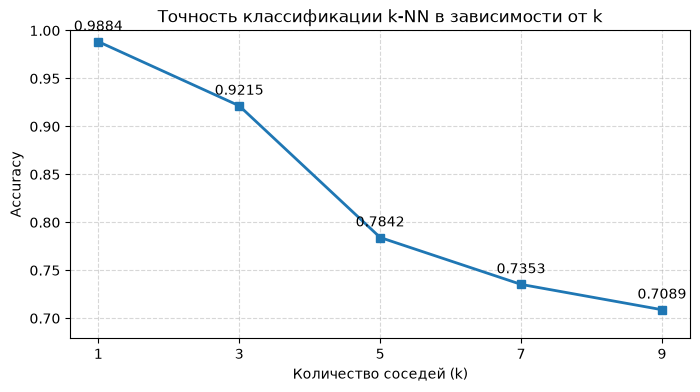

In [9]:
plt.figure(figsize=(8, 4))
ks = list(scores_by_k.keys())
accs = list(scores_by_k.values())

plt.plot(ks, accs, marker='s', linewidth=2)
for k_val, acc_val in zip(ks, accs):
    plt.annotate(f"{acc_val:.4f}", (k_val, acc_val), textcoords="offset points", xytext=(0, 8), ha='center')

plt.title("Точность классификации k-NN в зависимости от k")
plt.xlabel("Количество соседей (k)")
plt.ylabel("Accuracy")
plt.xticks(ks)
plt.ylim(min(accs) - 0.03, min(1.0, max(accs) + 0.02))
plt.grid(True, linestyle='--', alpha=0.5)
plt.show()

In [ ]:
test_pool = {}
for idx, lbl in enumerate(y_test):
    test_pool.setdefault(lbl, []).append(idx)

vocab = sorted(test_pool.keys())

def build_handwritten_sample(words_count=3, len_range=(2, 4), border=12):
    words = [
        ''.join(random.choices(vocab, k=random.randint(*len_range)))
        for _ in range(words_count)
    ]
    gt_text = ' '.join(words)

    tile_side = IMG_DIM + 2 * border
    glyph_arrays = []
    stitched_parts = []

    for ch in gt_text:
        if ch == ' ':
            stitched_parts.append(np.zeros((tile_side, tile_side), dtype=np.float32))
        else:
            sample_idx = random.choice(test_pool[ch])
            glyph = X_test[sample_idx].reshape(IMG_DIM, IMG_DIM)
            padded = np.pad(glyph, pad_width=border, mode='constant', constant_values=0.0)
            glyph_arrays.append(padded)
            stitched_parts.append(padded)

    combined_image = np.hstack(stitched_parts)
    return gt_text, glyph_arrays, combined_image

NUM_SAMPLES = 10
generated_dataset = [build_handwritten_sample() for _ in range(NUM_SAMPLES)]
print(f"Сгенерировано тестовых последовательностей: {len(generated_dataset)}")

Сгенерировано тестовых последовательностей: 10


In [ ]:
def recognize_handwritten_line(line_img, model=optimal_knn, gap_for_space=55):
    gray_u8 = (line_img * 255).astype(np.uint8)
    _, binary = cv2.threshold(gray_u8, 30, 255, cv2.THRESH_BINARY)

    morph_kernel = np.ones((4, 2), np.uint8)
    connected = cv2.dilate(binary, morph_kernel, iterations=1)
    contours, _ = cv2.findContours(connected, cv2.RETR_EXTERNAL, cv2.CHAIN_APPROX_SIMPLE)

    bboxes = []
    for cnt in contours:
        x, y, w, h = cv2.boundingRect(cnt)
        if w >= 7 or h >= 9:
            x0 = max(0, x + 1)
            y0 = max(0, y + 1)
            x1 = min(gray_u8.shape[1], x + w - 1)
            y1 = min(gray_u8.shape[0], y + h - 1)
            if x1 > x0 and y1 > y0:
                bboxes.append((x0, y0, x1 - x0, y1 - y0))

    bboxes.sort(key=lambda box: box[0])

    top_margin, side_margin = 28, 12
    annotated = cv2.copyMakeBorder(
        cv2.cvtColor(gray_u8, cv2.COLOR_GRAY2RGB),
        top_margin, side_margin, side_margin, side_margin,
        cv2.BORDER_CONSTANT, value=(0, 0, 0)
    )

    output_chars = []
    last_x_end = None

    for (x, y, w, h) in bboxes:
        if last_x_end is not None and (x - last_x_end) > gap_for_space:
            output_chars.append(' ')

        patch = line_img[y:y + h, x:x + w]
        canvas_size = max(w, h, IMG_DIM)
        square = np.zeros((canvas_size, canvas_size), dtype=np.float32)

        dy = (canvas_size - h) // 2
        dx = (canvas_size - w) // 2
        square[dy:dy + h, dx:dx + w] = patch

        if canvas_size != IMG_DIM:
            square = cv2.resize(square, (IMG_DIM, IMG_DIM), interpolation=cv2.INTER_AREA)

        predicted_symbol = model.predict(square.reshape(1, -1))[0]
        output_chars.append(predicted_symbol)
        last_x_end = x + w

        bx, by = x + side_margin, y + top_margin
        cv2.rectangle(annotated, (bx, by), (bx + w, by + h), (0, 90, 255), 1)
        cv2.putText(annotated, predicted_symbol, (bx, by - 6), cv2.FONT_HERSHEY_SIMPLEX, 0.55, (255, 40, 40), 1)

    return ''.join(output_chars), annotated

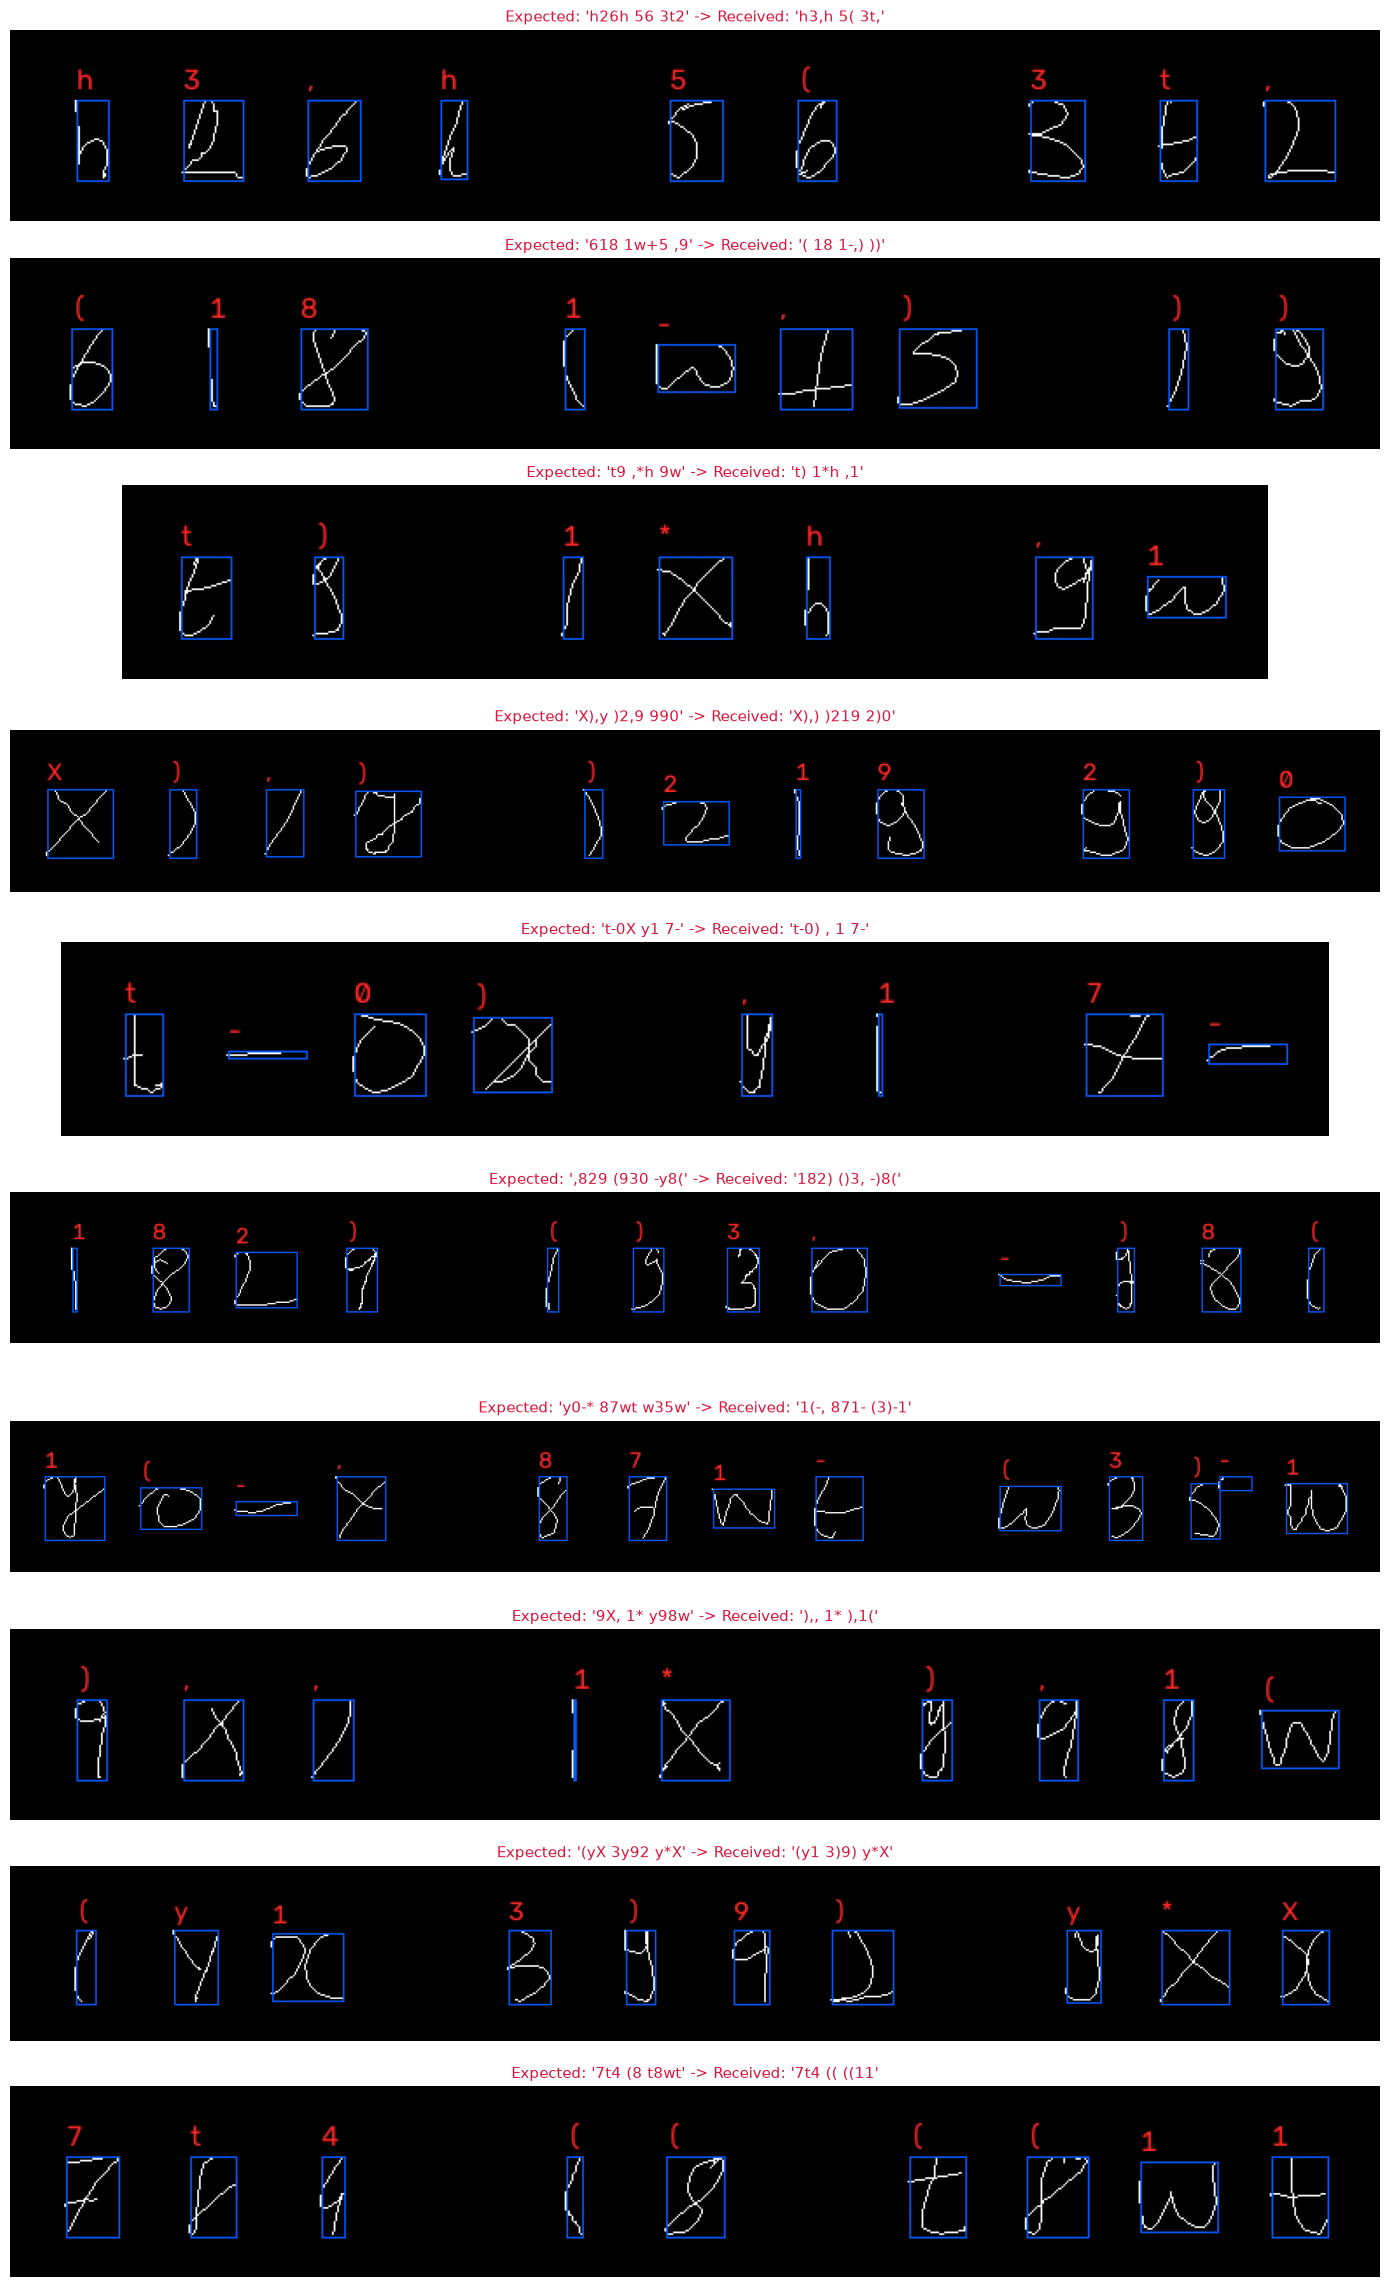

Полностью распознано строк: 0 из 10 (0%)


In [15]:
n_rows = len(generated_dataset)
fig, axes = plt.subplots(n_rows, 1, figsize=(14, 2.3 * n_rows))
if n_rows == 1:
    axes = [axes]

exact_matches = 0

for ax, (true_str, _, seq_img) in zip(axes, generated_dataset):
    pred_str, vis_canvas = recognize_handwritten_line(seq_img)
    is_correct = (true_str == pred_str)
    if is_correct:
        exact_matches += 1

    ax.imshow(vis_canvas)
    ax.set_title(
        f"Expected: '{true_str}' -> Received: '{pred_str}'",
        color='green' if is_correct else 'crimson',
        fontsize=11
    )
    ax.axis('off')

plt.tight_layout()
plt.show()

print(f"Полностью распознано строк: {exact_matches} из {n_rows} ({exact_matches / n_rows:.0%})")